In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv(r"C:\Users\Hello\Downloads\ANN_Diabetes_Dataset_75000Rows_13Columns_NoNull.csv")
df.head()

,Age,Gender,BMI,Glucose,BloodPressure,Insulin,HbA1c,PhysicalActivity,FamilyHistory,Smoking,StressLevel,SleepHours,Diabetes
0,24,Female,19.2,174,94,70,10.4,8.7,No,No,6,9.1,0
1,38,Male,25.4,155,149,140,5.6,9.1,Yes,No,2,4.0,0
2,75,Male,39.6,93,145,87,5.4,9.1,No,No,10,6.9,0
3,78,Male,36.2,157,126,262,5.9,6.1,No,Yes,7,9.4,1
4,83,Female,34.1,194,126,229,7.1,0.3,Yes,Yes,8,7.9,1


In [4]:
df.shape

(75000, 13)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               75000 non-null  int64  
 1   Gender            75000 non-null  str    
 2   BMI               75000 non-null  float64
 3   Glucose           75000 non-null  int64  
 4   BloodPressure     75000 non-null  int64  
 5   Insulin           75000 non-null  int64  
 6   HbA1c             75000 non-null  float64
 7   PhysicalActivity  75000 non-null  float64
 8   FamilyHistory     75000 non-null  str    
 9   Smoking           75000 non-null  str    
 10  StressLevel       75000 non-null  int64  
 11  SleepHours        75000 non-null  float64
 12  Diabetes          75000 non-null  int64  
dtypes: float64(4), int64(6), str(3)
memory usage: 8.2 MB


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               75000 non-null  int64  
 1   Gender            75000 non-null  str    
 2   BMI               75000 non-null  float64
 3   Glucose           75000 non-null  int64  
 4   BloodPressure     75000 non-null  int64  
 5   Insulin           75000 non-null  int64  
 6   HbA1c             75000 non-null  float64
 7   PhysicalActivity  75000 non-null  float64
 8   FamilyHistory     75000 non-null  str    
 9   Smoking           75000 non-null  str    
 10  StressLevel       75000 non-null  int64  
 11  SleepHours        75000 non-null  float64
 12  Diabetes          75000 non-null  int64  
dtypes: float64(4), int64(6), str(3)
memory usage: 8.2 MB


In [7]:
df.describe()

,Age,BMI,Glucose,BloodPressure,Insulin,HbA1c,PhysicalActivity,StressLevel,SleepHours,Diabetes
count,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000
mean,51.434333,29.500252,145.155853,120.121693,157.755213,7.999189,5.007619,5.486080,7.000120,0.587293
std,19.677024,7.223969,43.598733,34.929453,82.634443,2.025648,2.884813,2.872021,1.734277,0.492324
min,18.000000,17.000000,70.000000,60.000000,15.000000,4.500000,0.000000,1.000000,4.000000,0.000000
25%,34.000000,23.200000,107.000000,90.000000,86.000000,6.200000,2.500000,3.000000,5.500000,0.000000
50%,51.000000,29.500000,145.000000,120.000000,158.000000,8.000000,5.000000,5.000000,7.000000,1.000000
75%,69.000000,35.800000,183.000000,150.000000,229.000000,9.800000,7.500000,8.000000,8.500000,1.000000
max,85.000000,42.000000,220.000000,180.000000,300.000000,11.500000,10.000000,10.000000,10.000000,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

Age                 0
Gender              0
BMI                 0
Glucose             0
BloodPressure       0
Insulin             0
HbA1c               0
PhysicalActivity    0
FamilyHistory       0
Smoking             0
StressLevel         0
SleepHours          0
Diabetes            0
dtype: int64

### Data preprocessing

In [18]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [19]:
df.head()

,Age,Gender,BMI,Glucose,BloodPressure,Insulin,HbA1c,PhysicalActivity,FamilyHistory,Smoking,StressLevel,SleepHours,Diabetes
0,24,Female,19.2,174,94,70,10.4,8.7,No,No,6,9.1,0
1,38,Male,25.4,155,149,140,5.6,9.1,Yes,No,2,4.0,0
2,75,Male,39.6,93,145,87,5.4,9.1,No,No,10,6.9,0
3,78,Male,36.2,157,126,262,5.9,6.1,No,Yes,7,9.4,1
4,83,Female,34.1,194,126,229,7.1,0.3,Yes,Yes,8,7.9,1


In [20]:
num_col=['Age','BMI','Glucose','BloodPressure','Insulin','HbA1c','PhysicalActivity','StressLevel','SleepHours']
cat_col=['Gender','FamilyHistory','Smoking']

In [21]:
num_pipe=Pipeline([('scaling',StandardScaler())])
cat_pipe=Pipeline([('Encoder',OneHotEncoder(handle_unknown='ignore',drop='first'))])

In [22]:
num_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
cat_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",'first'
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not e

In [24]:
preprocessor=ColumnTransformer([('Scaling',num_pipe,num_col),
                                ('Encodig',cat_pipe,cat_col)])

In [25]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Scaling', ...), ('Encodig', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

In [26]:
x=df.drop(columns=['Diabetes'])
y=df['Diabetes']

In [27]:
x

,Age,Gender,BMI,Glucose,BloodPressure,Insulin,HbA1c,PhysicalActivity,FamilyHistory,Smoking,StressLevel,SleepHours
0,24,Female,19.2,174,94,70,10.4,8.7,No,No,6,9.1
1,38,Male,25.4,155,149,140,5.6,9.1,Yes,No,2,4.0
2,75,Male,39.6,93,145,87,5.4,9.1,No,No,10,6.9
3,78,Male,36.2,157,126,262,5.9,6.1,No,Yes,7,9.4
4,83,Female,34.1,194,126,229,7.1,0.3,Yes,Yes,8,7.9
...,...,...,...,...,...,...,...,...,...,...,...,...
74995,21,Male,31.7,177,62,243,10.0,6.3,Yes,Yes,5,8.6
74996,42,Female,25.8,131,152,248,10.6,5.4,Yes,No,3,7.5
74997,72,Female,41.3,97,110,134,8.6,2.2,Yes,No,9,4.4
74998,27,Female,37.6,129,166,232,9.4,3.7,Yes,Yes,1,8.9


In [28]:
x_prep=preprocessor.fit_transform(x)
x_prep

array([[-1.39424113, -1.4258533 ,  0.66158663, ...,  0.        ,
         0.        ,  0.        ],
       [-0.68274668, -0.56759367,  0.22579125, ...,  1.        ,
         1.        ,  0.        ],
       [ 1.19763149,  1.39809774, -1.19627791, ...,  1.        ,
         0.        ,  0.        ],
       ...,
       [ 1.0451684 ,  1.63342699, -1.10453151, ...,  0.        ,
         1.        ,  0.        ],
       [-1.24177803,  1.12123979, -0.37056033, ...,  0.        ,
         1.        ,  1.        ],
       [ 0.02874776, -1.4396962 , -1.21921451, ...,  1.        ,
         1.        ,  1.        ]], shape=(75000, 12))

In [29]:
x_train,x_test,y_train,y_test=train_test_split(x_prep,y,train_size=0.8,random_state=42)

In [30]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((60000, 12), (15000, 12), (60000,), (15000,))

### Model Build

In [31]:
from keras.models import Sequential
from keras.layers import Input,Dense

In [32]:
model=Sequential()
model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(32,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [33]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 449 (1.75 KB)

 Trainable params: 449 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [36]:
model.fit(x_train,y_train,epochs=20,validation_data=(x_test,y_test),batch_size=128)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 30s 15ms/step - accuracy: 0.8373 - loss: 0.3750 - val_accuracy: 0.8791 - val_loss: 0.2702
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8850 - loss: 0.2550 - val_accuracy: 0.8887 - val_loss: 0.2486
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8901 - loss: 0.2428 - val_accuracy: 0.8911 - val_loss: 0.2430
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8921 - loss: 0.2389 - val_accuracy: 0.8914 - val_loss: 0.2411
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8939 - loss: 0.2343 - val_accuracy: 0.8955 - val_loss: 0.2343
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8974 - loss: 0.2267 - val_accuracy: 0.8997 - val_loss: 0.2246
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9031 - loss: 0.2154 - val_accuracy: 0.9053 - val_loss: 0.2123
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9111 - loss: 0.2021 - val_accuracy: 

In [37]:
import seaborn as sns

<Axes: >

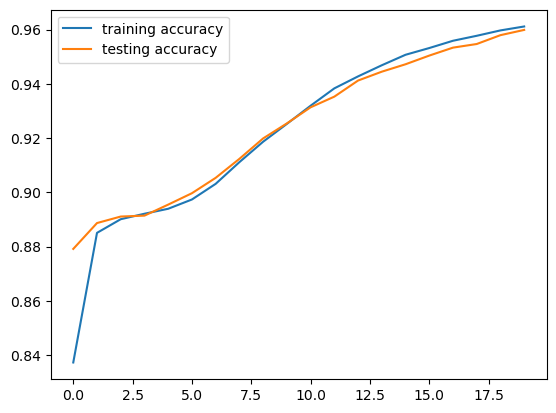

In [38]:
sns.lineplot(x=model.history.epoch,y=model.history.history['accuracy'],label='training accuracy')
sns.lineplot(x=model.history.epoch,y=model.history.history['val_accuracy'],label='testing accuracy')

<Axes: >

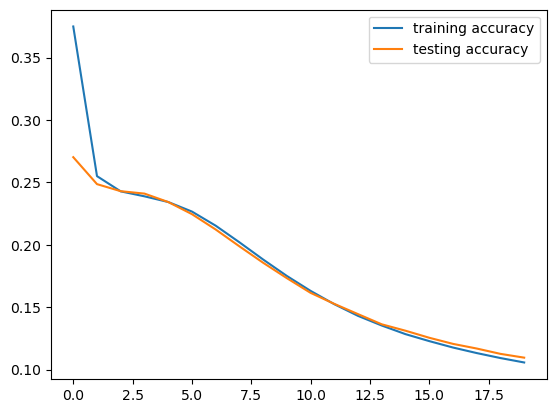

In [39]:
sns.lineplot(x=model.history.epoch,y=model.history.history['loss'],label='training accuracy')
sns.lineplot(x=model.history.epoch,y=model.history.history['val_loss'],label='testing accuracy')

In [40]:
from sklearn.metrics import classification_report

In [41]:
y_pred=np.where(model.predict(x_test)>0.5,1,0)
y_pred

469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [1]], shape=(15000, 1))

In [42]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.95      0.96      0.95      6265
           1       0.97      0.96      0.97      8735

    accuracy                           0.96     15000
   macro avg       0.96      0.96      0.96     15000
weighted avg       0.96      0.96      0.96     15000



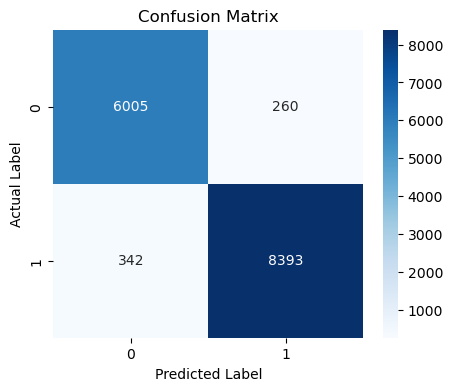

In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [44]:
from sklearn.utils.class_weight import compute_class_weight

In [45]:
class_weight=compute_class_weight(class_weight='balanced',classes=np.unique(y_train),y=y_train)
dict_class={i:class_weight[i] for i in range(len(class_weight))}
dict_class

{0: np.float64(1.2151652624756968), 1: np.float64(0.8495695514272769)}

In [46]:
import optuna
from keras.regularizers import L1L2

In [47]:
from keras.optimizers import Adam,RMSprop,SGD
from keras.layers import Dropout,BatchNormalization
from keras.regularizers import L1L2
from keras.callbacks import EarlyStopping

def objective(trail):
    n_layers=trail.suggest_int('n_layers',1,10)
    epochs=trail.suggest_int('epochs',1,10)
    lr_rate=trail.suggest_float('learning rate',1e-4,1e-2,log=True)
    batch_size=trail.suggest_int('batch_size',12,128)
    activation=trail.suggest_categorical('activation',['relu','tanh'])
    optimizers=trail.suggest_categorical('optimizers',['Adam','RMSprop','SGD'])

    model=Sequential()
    model.add(Input(shape=(x_train.shape[1],)))

    for i in range(n_layers):

        n_units=trail.suggest_int(f'units{i}',1,100)
        dropout=trail.suggest_float(f'dropout{i}',0.1,0.5)
        strength=trail.suggest_float(f'regularization{i}',1e-4,1e-2,log=True)

        model.add(Dense(units=n_units,activation=activation,kernel_regularizer=L1L2(l1=strength,l2=strength)))
        model.add(Dropout(rate=dropout))
        model.add(BatchNormalization())

    model.add(Dense(1,activation='sigmoid'))

    early_stopping=EarlyStopping(monitor='val_recall',min_delta=0.001,patience=3)

    if optimizers=='Adam':
        optimizer=Adam(learning_rate=lr_rate)
    elif optimizers=='RMSprop':
        optimizer=RMSprop(learning_rate=lr_rate)
    else:
        optimizer=SGD(learning_rate=lr_rate)

    model.compile(optimizer=optimizer,loss='binary_crossentropy',metrics=['recall'])

    model.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test),class_weight=dict_class,callbacks=early_stopping)

    return max(model.history.history['val_recall'])

In [48]:
study=optuna.create_study(direction='maximize')
study.optimize(objective,n_trials=5)

[I 2026-07-27 20:23:23,399] A new study created in memory with name: no-name-1535a30a-f8d6-44b9-9db3-baf58e4c916e


Epoch 1/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 25s 9ms/step - loss: 0.8124 - recall: 0.8177 - val_loss: 0.5119 - val_recall: 0.8622
Epoch 2/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - loss: 0.4553 - recall: 0.8533 - val_loss: 0.3784 - val_recall: 0.8550
Epoch 3/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.3715 - recall: 0.8541 - val_loss: 0.3322 - val_recall: 0.8611
Epoch 4/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.3367 - recall: 0.8557 - val_loss: 0.3139 - val_recall: 0.8583


[I 2026-07-27 20:24:22,194] Trial 0 finished with value: 0.8621637225151062 and parameters: {'n_layers': 1, 'epochs': 10, 'learning rate': 0.0002749443462661423, 'batch_size': 50, 'activation': 'tanh', 'optimizers': 'RMSprop', 'units0': 89, 'dropout0': 0.20176544706162103, 'regularization0': 0.0054499382578003935}. Best is trial 0 with value: 0.8621637225151062.


Epoch 1/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.6867 - recall: 0.7894 - val_loss: 0.5097 - val_recall: 0.9794
Epoch 2/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3720 - recall: 0.8588 - val_loss: 0.3307 - val_recall: 0.8710
Epoch 3/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.3589 - recall: 0.8576 - val_loss: 0.3523 - val_recall: 0.8117
Epoch 4/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.3572 - recall: 0.8547 - val_loss: 0.3451 - val_recall: 0.8493


[I 2026-07-27 20:24:51,960] Trial 1 finished with value: 0.9793932437896729 and parameters: {'n_layers': 4, 'epochs': 9, 'learning rate': 0.0025951506993947293, 'batch_size': 128, 'activation': 'tanh', 'optimizers': 'RMSprop', 'units0': 8, 'dropout0': 0.44207577942558807, 'regularization0': 0.005360806065863995, 'units1': 24, 'dropout1': 0.14283269594209178, 'regularization1': 0.0031395958215760167, 'units2': 22, 'dropout2': 0.36888490148420894, 'regularization2': 0.0014609276498339554, 'units3': 96, 'dropout3': 0.31177640943190915, 'regularization3': 0.00019441892905090887}. Best is trial 1 with value: 0.9793932437896729.


Epoch 1/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - loss: 4.1505 - recall: 0.7911 - val_loss: 1.4529 - val_recall: 0.9062
Epoch 2/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.8043 - recall: 0.8645 - val_loss: 0.5163 - val_recall: 0.9197
Epoch 3/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4269 - recall: 0.8779 - val_loss: 0.3204 - val_recall: 0.9844
Epoch 4/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.3411 - recall: 0.9044 - val_loss: 0.2537 - val_recall: 0.9794
Epoch 5/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.3120 - recall: 0.9154 - val_loss: 0.2488 - val_recall: 0.9240
Epoch 6/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.2934 - recall: 0.9243 - val_loss: 0.2731 - val_recall: 0.9311


[I 2026-07-27 20:25:38,214] Trial 2 finished with value: 0.9844304323196411 and parameters: {'n_layers': 5, 'epochs': 7, 'learning rate': 0.00048616002827822424, 'batch_size': 76, 'activation': 'relu', 'optimizers': 'RMSprop', 'units0': 88, 'dropout0': 0.19965449707599317, 'regularization0': 0.005356296665626233, 'units1': 34, 'dropout1': 0.318358852186027, 'regularization1': 0.0030046746117448437, 'units2': 54, 'dropout2': 0.19260508612383276, 'regularization2': 0.005692704047438546, 'units3': 84, 'dropout3': 0.23024323317469664, 'regularization3': 0.00849791117802244, 'units4': 87, 'dropout4': 0.3776609237346229, 'regularization4': 0.0005146973402831649}. Best is trial 2 with value: 0.9844304323196411.


Epoch 1/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - loss: 1.2563 - recall: 0.7989 - val_loss: 0.5793 - val_recall: 0.8878
Epoch 2/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 33s 13ms/step - loss: 0.5838 - recall: 0.8352 - val_loss: 0.4952 - val_recall: 0.8405
Epoch 3/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - loss: 0.5697 - recall: 0.8389 - val_loss: 0.5579 - val_recall: 0.7864
Epoch 4/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 28s 10ms/step - loss: 0.5626 - recall: 0.8366 - val_loss: 0.5109 - val_recall: 0.9085
Epoch 5/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - loss: 0.5573 - recall: 0.8406 - val_loss: 0.4845 - val_recall: 0.8136


[I 2026-07-27 20:28:00,177] Trial 3 finished with value: 0.9085289239883423 and parameters: {'n_layers': 8, 'epochs': 5, 'learning rate': 0.0013917893898398328, 'batch_size': 24, 'activation': 'tanh', 'optimizers': 'RMSprop', 'units0': 35, 'dropout0': 0.3070686254098216, 'regularization0': 0.00037588108754955815, 'units1': 2, 'dropout1': 0.10086138604523592, 'regularization1': 0.005515619014235261, 'units2': 56, 'dropout2': 0.32720129483689975, 'regularization2': 0.004185241044678071, 'units3': 85, 'dropout3': 0.47683725046364966, 'regularization3': 0.004939485669321533, 'units4': 95, 'dropout4': 0.19558907585720575, 'regularization4': 0.00011482841734150083, 'units5': 85, 'dropout5': 0.28391002756130557, 'regularization5': 0.000670337892099921, 'units6': 34, 'dropout6': 0.11938260037273998, 'regularization6': 0.009001309548253265, 'units7': 79, 'dropout7': 0.16938738515299556, 'regularization7': 0.0015169747412208485}. Best is trial 2 with value: 0.9844304323196411.


Epoch 1/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 32s 9ms/step - loss: 1.1586 - recall: 0.7850 - val_loss: 0.5893 - val_recall: 0.8332
Epoch 2/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - loss: 0.6390 - recall: 0.8159 - val_loss: 0.5668 - val_recall: 0.7880
Epoch 3/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - loss: 0.6090 - recall: 0.8195 - val_loss: 0.5474 - val_recall: 0.7977
Epoch 4/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 0.5897 - recall: 0.8180 - val_loss: 0.5029 - val_recall: 0.9153
Epoch 5/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - loss: 0.5784 - recall: 0.8191 - val_loss: 0.5411 - val_recall: 0.8940
Epoch 6/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 0.5744 - recall: 0.8202 - val_loss: 0.5265 - val_recall: 0.8206
Epoch 7/7
2308/2308 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - loss: 0.5692 - recall: 0.8197 - val_loss: 0.5252 - val_recall: 0.8618


[I 2026-07-27 20:30:26,399] Trial 4 finished with value: 0.9152833223342896 and parameters: {'n_layers': 10, 'epochs': 7, 'learning rate': 0.0025588691427120493, 'batch_size': 26, 'activation': 'tanh', 'optimizers': 'RMSprop', 'units0': 62, 'dropout0': 0.48477001588003943, 'regularization0': 0.009455181027250972, 'units1': 28, 'dropout1': 0.3529309095358877, 'regularization1': 0.005129458056595677, 'units2': 9, 'dropout2': 0.135176224043411, 'regularization2': 0.0006103036252573566, 'units3': 54, 'dropout3': 0.30731591167248296, 'regularization3': 0.00631619673174649, 'units4': 65, 'dropout4': 0.1370850967680465, 'regularization4': 0.00026578913071270113, 'units5': 5, 'dropout5': 0.16070535215081105, 'regularization5': 0.00013259891099847917, 'units6': 83, 'dropout6': 0.3655297989975961, 'regularization6': 0.0005701361817947885, 'units7': 69, 'dropout7': 0.13168651168895879, 'regularization7': 0.0005684900053593564, 'units8': 60, 'dropout8': 0.21060762346288275, 'regularization8': 0.00

In [49]:
study.best_params

{'n_layers': 5,
 'epochs': 7,
 'learning rate': 0.00048616002827822424,
 'batch_size': 76,
 'activation': 'relu',
 'optimizers': 'RMSprop',
 'units0': 88,
 'dropout0': 0.19965449707599317,
 'regularization0': 0.005356296665626233,
 'units1': 34,
 'dropout1': 0.318358852186027,
 'regularization1': 0.0030046746117448437,
 'units2': 54,
 'dropout2': 0.19260508612383276,
 'regularization2': 0.005692704047438546,
 'units3': 84,
 'dropout3': 0.23024323317469664,
 'regularization3': 0.00849791117802244,
 'units4': 87,
 'dropout4': 0.3776609237346229,
 'regularization4': 0.0005146973402831649}

In [50]:
best_params = study.best_params
n_layers = best_params['n_layers']
epochs = best_params['epochs']
lr_rate = best_params['learning rate']  # Fixed typo: lr_rate
batch_size = best_params['batch_size']

model = Sequential()
model.add(Input(shape=(x_train.shape[1],)))

# Hidden layers loop
for i in range(n_layers):
    units = best_params[f'units{i}']
    dropout = best_params[f'dropout{i}']
    strength = best_params[f'regularization{i}']

    model.add(
        Dense(
            units=units,
            activation='relu',
            kernel_regularizer=L1L2(l1=strength, l2=strength),
        )
    )
    model.add(Dropout(dropout))
    model.add(BatchNormalization())

# Output layer (unindented, outside the loop)
model.add(Dense(1, activation='sigmoid'))

early_stopping = EarlyStopping(
    monitor='val_recall', min_delta=0.01, patience=3, restore_best_weights=True
)

model.compile(
    optimizer=RMSprop(learning_rate=lr_rate),
    loss='binary_crossentropy',
    metrics=['recall'],
)

model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_test, y_test),
    class_weight=dict_class,
    callbacks=[early_stopping],  # Wrapped in a list
)

Epoch 1/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - loss: 4.2489 - recall: 0.7760 - val_loss: 1.5144 - val_recall: 0.9420
Epoch 2/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.8403 - recall: 0.8532 - val_loss: 0.5300 - val_recall: 0.9309
Epoch 3/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 0.4299 - recall: 0.8856 - val_loss: 0.3069 - val_recall: 0.9170
Epoch 4/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.3441 - recall: 0.9061 - val_loss: 0.2599 - val_recall: 0.9540
Epoch 5/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - loss: 0.3170 - recall: 0.9180 - val_loss: 0.3051 - val_recall: 0.9108
Epoch 6/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.3001 - recall: 0.9202 - val_loss: 0.2859 - val_recall: 0.9080
Epoch 7/7
790/790 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.2935 - recall: 0.9233 - val_loss: 0.2604 - val_recall: 0.9256


In [51]:
y_pred=np.where(model.predict(x_test)>0.5,1,0)

469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [52]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      0.97      0.95      6265
           1       0.98      0.95      0.96      8735

    accuracy                           0.96     15000
   macro avg       0.96      0.96      0.96     15000
weighted avg       0.96      0.96      0.96     15000



In [53]:
import pickle
with open(r"C:\Users\Hello\Downloads\healthcare\preprocessor.pkl",'wb') as f:
    pickle.dump(preprocessor,f)

In [54]:
model.save(r"C:\Users\Hello\Downloads\healthcare\architecture.keras")

In [55]:
model.save(r"C:\Users\Hello\Downloads\healthcare\architecture.h5")

In [56]:
from keras.models import load_model

deployment=load_model(r"C:\Users\Hello\Downloads\healthcare\architecture.keras")